# Visualização de um espectrograma

Além de representar os dados nos domínios do tempo ou da frequência, podemos visualizar informações de tempo e frequência simultaneamente por meio de um **espectrograma**. Uma das técnicas utilizadas para isso é a **transformada Q** (*Q-transform*), que emprega uma base de *wavelets* para obter uma representação do sinal no plano tempo-frequência.

Neste notebook, adicionaremos um sinal simulado a um ruído branco e, em seguida, visualizaremos o resultado na forma de um espectrograma.


In [ ]:
# -- Para executar no Google Colab, descomente a linha abaixo.
# !pip install -q pycbc gwpy


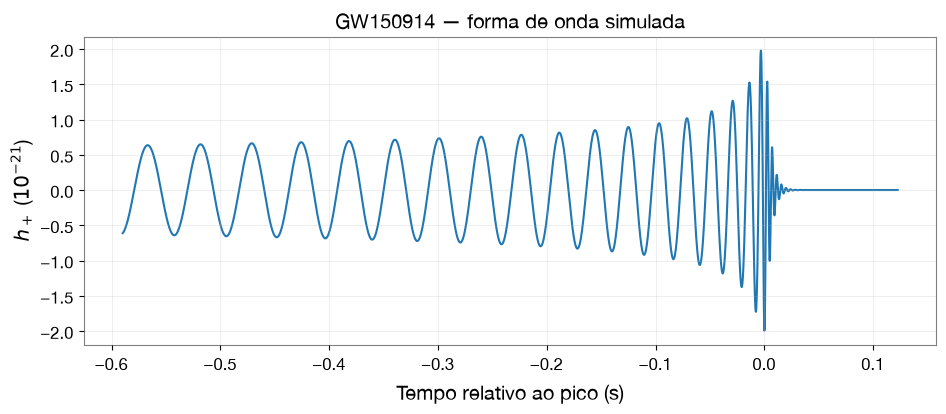

Arquivo criado: GW150914_PyCBC_simulado.txt
Número de amostras: 2919
Duração: 0.712646484375 s


In [2]:

import matplotlib.pyplot as plt
import numpy as np
from pycbc.waveform import get_td_waveform

# Parâmetros da simulação
fs = 4096
apx = 'SEOBNRv2'

m1 = 44       # massas solares
m2 = 30       # massas solares
dist = 410    # Mpc
fmin = 20     # Hz

# Gerar as duas polarizações
hp, hc = get_td_waveform(
    approximant=apx,
    mass1=m1,
    mass2=m2,
    delta_t=1.0/fs,
    distance=dist,
    f_lower=fmin,
    inclination=0.0,
    coa_phase=0.0,
    spin1z=0.0,
    spin2z=0.0
)

# Vetores NumPy
tempo = np.asarray(hp.sample_times)
h = np.asarray(hp)

# Definir t = 0 no pico de |h+|
tempo = tempo - tempo[np.argmax(np.abs(h))]

# Visualizar o sinal
plt.figure(figsize=(11, 4))
plt.plot(tempo, h / 1e-21)
plt.xlabel('Tempo relativo ao pico (s)')
plt.ylabel(r'$h_+$ ($10^{-21}$)')
plt.title('GW150914 — forma de onda simulada')
plt.grid(alpha=0.3)
plt.show()

# Salvar no mesmo padrão de escala do arquivo GWOSC
arquivo = 'GW150914_PyCBC_simulado.txt'

np.savetxt(
    arquivo,
    np.column_stack((tempo, h * 1e21)),
    fmt='%.9e',
    header='time (seconds)    strain * 1.e21'
)

print('Arquivo criado:', arquivo)
print('Número de amostras:', len(h))
print('Duração:', len(h)/fs, 's')


In [ ]:
# -- Calcular a transformada Q e exibir o espectrograma
plot = data.q_transform(outseg=(4, 5), qrange=(10, 30)).plot()

ax = plot.gca()
ax.set_xscale('seconds')
ax.set_yscale('log')
ax.set_ylim(20, 1000)
ax.set_xlabel('Tempo (s)')
ax.set_ylabel('Frequência (Hz)')
ax.set_title('Espectrograma pela transformada Q')


## Questões de verificação

1. Qual é a frequência do sinal nos instantes iniciais, cerca de 0,8 segundo antes da fusão?
2. Qual é a frequência do sinal próximo ao instante da fusão?
3. Por que a frequência aumenta à medida que nos aproximamos da fusão?


## Pratique com Python

1. Tente gerar os mesmos gráficos para um sinal com `mass1 = mass2 = 30` massas solares.
2. Quais diferenças você observa entre os sinais do sistema de menor massa e do sistema de maior massa?
